In [ ]:
import zipfile
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.models import load_model

In [ ]:
# STEP 1: EXTRACT ZIP FILE
zip_file_path = "/content/archive (22).zip"
extract_folder = "traffic_sign"

# Extract ZIP file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_folder)

# Define dataset directories
train_dir = os.path.join(extract_folder, '/content/traffic_sign')
test_dir = os.path.join(extract_folder, '/content/traffic_sign')

In [ ]:
# STEP 2: DATA PREPROCESSING
img_size = (64, 64)
batch_size = 32

# Only rescale images
train_datagen = ImageDataGenerator(
    rescale=1.0/255,  # Normalize pixel values to [0,1]
    validation_split=0.2
)

# Training data generator
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

# Validation data generator
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)


Found 3168 images belonging to 5 classes.
Found 792 images belonging to 5 classes.


In [ ]:
# STEP 3: BUILD CNN MODEL

model = models.Sequential([
    layers.Conv2D(64, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(train_generator.num_classes, activation='softmax')
])

# Compile model
model.compile(optimizer=AdamW(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Print model summary
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 64)          │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 62, 62, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 29, 29, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 12, 12, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │       4,719,104 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │           1,285 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,224,325 (19.93 MB)

 Trainable params: 5,223,429 (19.93 MB)

 Non-trainable params: 896 (3.50 KB)

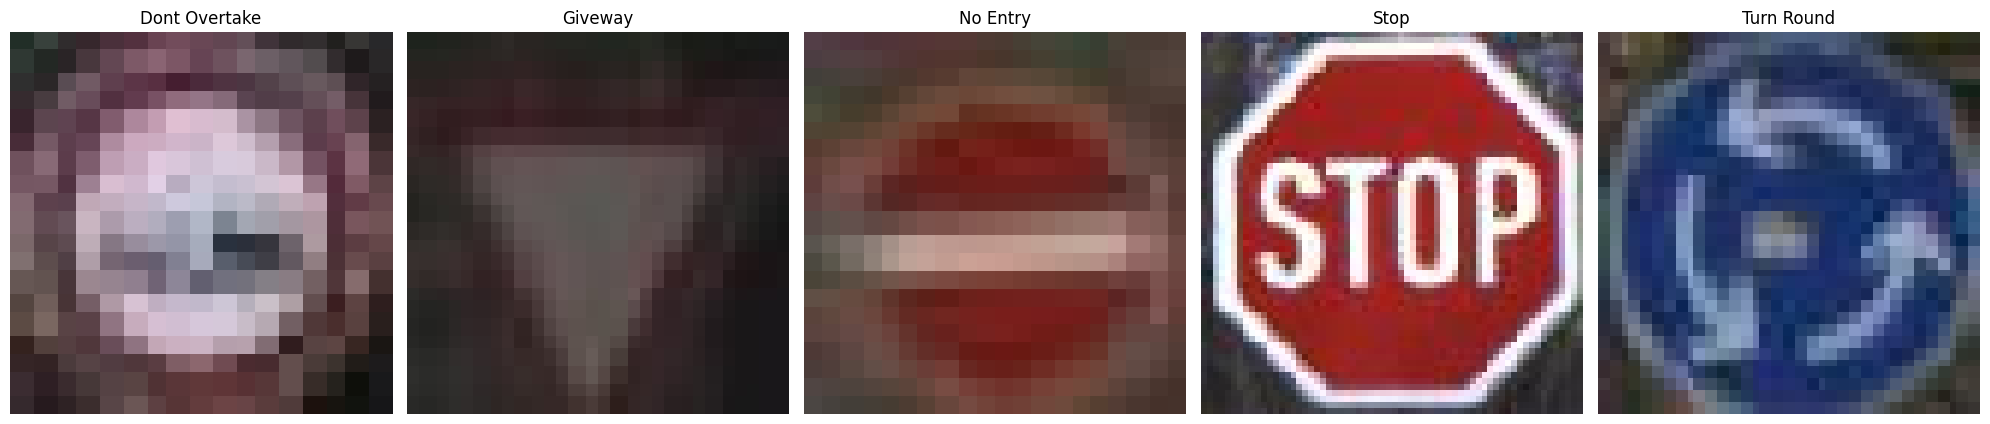

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random
import os

# Get class labels
class_labels = list(train_generator.class_indices.keys())

# Define number of classes
num_classes = len(class_labels)

# Set up a grid for displaying images
fig, axes = plt.subplots(1, num_classes, figsize=(20, 5))

# Loop through each class and display one image
for i, class_name in enumerate(class_labels):
    class_path = os.path.join(train_dir, class_name)  # Get class folder path
    image_name = random.choice(os.listdir(class_path))  # Pick a random image
    image_path = os.path.join(class_path, image_name)

    # Load and display image
    img = load_img(image_path, target_size=img_size)
    axes[i].imshow(img)
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Define Learning Rate Scheduler
lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

# STEP 4: TRAIN THE MODEL
epochs = 15

# Train the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    callbacks=[lr_scheduler]
)

# Print final training and validation accuracy
train_acc = history.history['accuracy'][-1]
val_acc = history.history['val_accuracy'][-1]

print(f"Final Training Accuracy: {train_acc * 100:.2f}%")
print(f"Final Validation Accuracy: {val_acc* 100:.2f}%")

Epoch 1/15


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


99/99 ━━━━━━━━━━━━━━━━━━━━ 86s 829ms/step - accuracy: 0.7605 - loss: 1.7786 - val_accuracy: 0.3636 - val_loss: 5.0562 - learning_rate: 0.0010
Epoch 2/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 81s 815ms/step - accuracy: 0.9667 - loss: 0.2964 - val_accuracy: 0.5644 - val_loss: 3.0025 - learning_rate: 0.0010
Epoch 3/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 81s 819ms/step - accuracy: 0.9830 - loss: 0.1523 - val_accuracy: 0.7462 - val_loss: 3.5067 - learning_rate: 0.0010
Epoch 4/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 81s 818ms/step - accuracy: 0.9860 - loss: 0.1395 - val_accuracy: 0.7740 - val_loss: 2.5139 - learning_rate: 0.0010
Epoch 5/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 87s 875ms/step - accuracy: 0.9943 - loss: 0.0632 - val_accuracy: 0.7955 - val_loss: 2.1561 - learning_rate: 0.0010
Epoch 6/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 85s 856ms/step - accuracy: 0.9901 - loss: 0.1360 - val_accuracy: 0.8472 - val_loss: 1.8076 - learning_rate: 0.0010
Epoch 7/15
99/99 ━━━━━━━━━━━━━━━━━━━━ 141s 840ms/step - accuracy: 0.9870 - loss: 0.1518 - val

In [ ]:
# STEP 5: EVALUATE THE MODEL

# Load test data
test_datagen = ImageDataGenerator(rescale=1.0/255)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# Evaluate model on test data
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

Found 3960 images belonging to 5 classes.
124/124 ━━━━━━━━━━━━━━━━━━━━ 24s 193ms/step - accuracy: 0.9984 - loss: 0.0098
Test Accuracy: 99.67%


In [ ]:
# STEP 6: SAVE THE MODEL

model.save("traffic_sign_regconition_model.h5")
print("Model saved as traffic_sign_model.h5")

Model saved as traffic_sign_model.h5


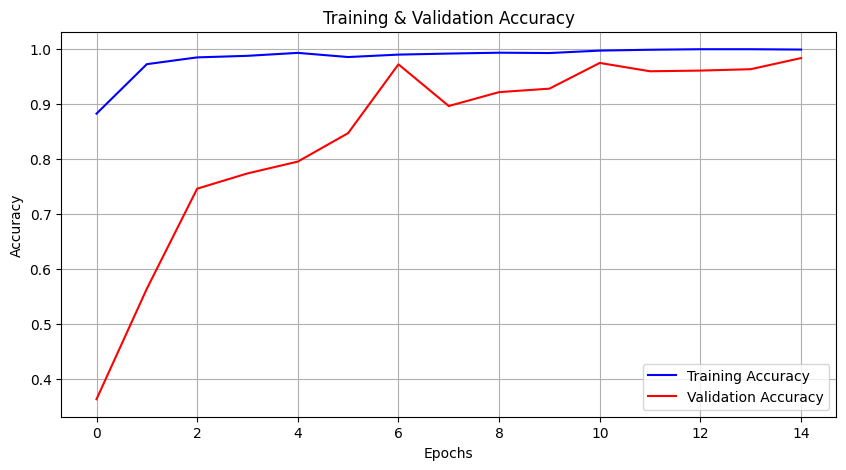

In [ ]:
import matplotlib.pyplot as plt

# Plot Training & Validation Accuracy
plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='red')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training & Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

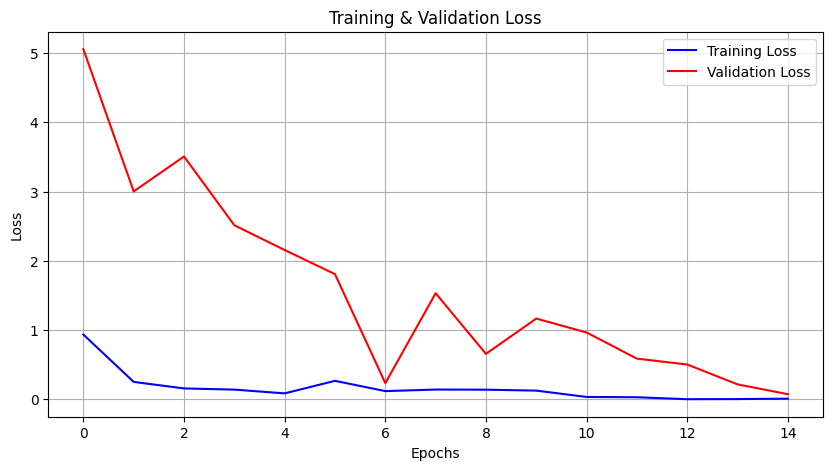

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='red')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


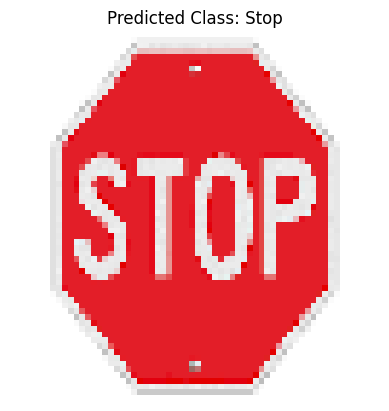

Predicted Class: Stop


In [ ]:
# STEP 7: MAKE PREDICTIONS ON NEW IMAGES

def predict_image_tta(img_path, model, class_indices):
    img = load_img(img_path, target_size=img_size)
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    augmented_images = np.array([img_array] * 5)  # Apply 5 variations
    # Remove the extra dimension using squeeze
    predictions = model.predict(np.squeeze(augmented_images, axis=1))
    predicted_class = np.argmax(np.mean(predictions, axis=0))  # Average predictions

    class_labels = {v: k for k, v in class_indices.items()}
    predicted_label = class_labels[predicted_class]

    # Display the image with prediction
    plt.imshow(img)
    plt.title(f"Predicted Class: {predicted_label}")
    plt.axis("off")
    plt.show()

    return predicted_label

# Get class indices
class_indices = train_generator.class_indices

# Test with a sample image
test_image_path = "/content/stop.png"  # Change path accordingly
predicted_class = predict_image_tta(test_image_path, model, class_indices)
print(f"Predicted Class: {predicted_class}")